<div
  style="
    background-color: #f0f0f0;
    color:rgb(56, 56, 56);
    padding: 8px;
    display: flex;
    align-items: center;
    gap: 100px;
  "
>
  <img src="./images/brand.svg" style="max-height: 80px;">
  <strong>
    AI Saga: Data Science and Machine Learning</br>
    3.lab.1. Wisconsin Cancer Classification - Neural Networks
  </strong>
</div>

In [1]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import seaborn as sns

from rich.table import Table
from rich.console import Console
from sklearn import svm

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

Visual configuration of Seaborn for more attractive graphics

In [2]:
sns.set_theme(style="whitegrid", palette="muted")
sns.set_context("notebook", font_scale=1.2)

Rich console instance to display results

In [3]:
console = Console()

## Data Loading

In [4]:
breast_cancer = load_breast_cancer(as_frame=True)
X = breast_cancer.data
y = breast_cancer.target

target_names = breast_cancer.target_names

diagnosis_labels = breast_cancer.target.map({0: target_names[0], 1: target_names[1]})

## Preprocessing of data

Split the data with all features into training and testing sets

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)

print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")

Training set size: (341, 30)
Test set size: (228, 30)


Method to escalate the data

In [6]:
def normalizer_data(scaler, X_train, X_test):
    
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled, X_test_scaled

Method to return dictionary of available normalization methods

In [7]:
def get_normalizations():
    
    return {
        "Min-Max": MinMaxScaler(),
        "Standard": StandardScaler(),
        "Mean Normalization": Normalizer(),
    }

normalizations = get_normalizations()

Method to return dictionary of available models

In [8]:
def get_all_models_dict():
    
    return {
        "Logistic Regression": {},
        "SVM Linear": {}, 
        "SVM RBF": {}
    }

## Training Methods

Method to train a regression model

In [9]:
def train_regression_model(X_train_scaled, y_train_data, X_test_scaled):
    
    model = LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000)
    model.fit(X_train_scaled, y_train_data)

    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    return model, y_train_pred, y_test_pred

Method to train a SVM model

In [10]:
def train_svm_model(X_train_scaled, y_train_data, X_test_scaled, kernel):
    
    svm_model = svm.SVC(kernel=kernel, C=100)
    svm_model.fit(X_train_scaled, y_train_data)

    svm_y_train_pred = svm_model.predict(X_train_scaled)
    svm_y_test_pred = svm_model.predict(X_test_scaled)

    return svm_model, svm_y_train_pred, svm_y_test_pred

## Evaluation Methods

Method to calculate metrics

In [11]:
def calculate_metrics_for_set(y_test, y_test_pred):
    
    acc = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred)
    recall = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)

    return acc, precision, recall, f1

def calculate_metrics(
    y_train_regression_model, y_train_regression_model_pred, y_test_model, y_test_model_pred
):

    acc_train, precision_train, recall_train, f1_train = calculate_metrics_for_set(
        y_train_regression_model, y_train_regression_model_pred
    )
    acc_test, precision_test, recall_test, f1_test = calculate_metrics_for_set(
        y_test_model, y_test_model_pred
    )

    return {
        "accuracy_score_train": acc_train,
        "precision_score_train": precision_train,
        "recall_score_train": recall_train,
        "f1_score_train": f1_train,
        "accuracy_score_test": acc_test,
        "precision_score_test": precision_test,
        "recall_score_test": recall_test,
        "f1_score_test": f1_test,
    }

## Visualization methods

Method to create the comparison table

In [12]:
def create_comparison_table(title, results):

    comparison_table_normalization = Table(title=title)

    comparison_table_normalization.add_column(
        "Model", justify="center", style="green", width=15
    )
    comparison_table_normalization.add_column(
        "Normalization", justify="left", style="cyan"
    )
    comparison_table_normalization.add_column(
        "Accuracy-\nTrain", justify="right", style="green"
    )
    comparison_table_normalization.add_column(
        "Accuracy-\nTest", justify="right", style="green"
    )
    comparison_table_normalization.add_column(
        "Precision-\nTrain", justify="right", style="green"
    )
    comparison_table_normalization.add_column(
        "Precision-\nTest", justify="right", style="green"
    )
    comparison_table_normalization.add_column(
        "Recall-\nTrain", justify="right", style="green"
    )
    comparison_table_normalization.add_column(
        "Recall-\nTest", justify="right", style="green"
    )
    comparison_table_normalization.add_column(
        "F1-Train", justify="right", style="green"
    )
    comparison_table_normalization.add_column("F1-Test", justify="right", style="green")

    for model_name, normalization_metrics in results.items():

        for normalization_type, metrics in normalization_metrics.items():
            comparison_table_normalization.add_row(
                model_name,
                normalization_type,
                f'{metrics["accuracy_score_train"]:.4f}',
                f'{metrics["accuracy_score_test"]:.4f}',
                f'{metrics["precision_score_train"]:.4f}',
                f'{metrics["precision_score_test"]:.4f}',
                f'{metrics["recall_score_train"]:.4f}',
                f'{metrics["recall_score_test"]:.4f}',
                f'{metrics["f1_score_train"]:.4f}',
                f'{metrics["f1_score_test"]:.4f}',
            )

    console.print(comparison_table_normalization)

Method to show the confusion matrix

In [13]:
def plot_confusion_matrix(cm, title, ax):

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")


def plot_confusion_matrix_comparison(y_test, rg_y_test_pred, svm_lin_y_test_pred, svm_rbf_y_test_pred):
    
    cm_reg = confusion_matrix(y_test, rg_y_test_pred)
    cm_svm_linear = confusion_matrix(y_test, svm_lin_y_test_pred)
    cm_svm_rbf = confusion_matrix(y_test, svm_rbf_y_test_pred)

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    plot_confusion_matrix(cm_reg, "Confusion Matrix - Logistic Regression", axes[0][0])
    plot_confusion_matrix(cm_svm_linear, "Confusion Matrix - SVM Linear", axes[0][1])
    plot_confusion_matrix(cm_svm_rbf, "Confusion Matrix - SVM RBF", axes[1][0])

    fig.delaxes(axes[1][1])
    
    plt.tight_layout()
    plt.show()

Method to show the decision boundary of a model in 2D

In [14]:
def plot_decision_boundary_2d(model, X_train, y_train, scaler, title):
    
    X_train_scaled = scaler.fit_transform(X_train)
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_train_scaled)

    color_map = matplotlib.colors.ListedColormap(['#FF0000', '#0000FF'])
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, s=40, cmap=color_map)

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    xy_original = pca.inverse_transform(xy)
    Z = model.decision_function(xy_original).reshape(XX.shape)

    if hasattr(model, "support_vectors_"):
        levels = [-1, 0, 1]
        linestyles = ['--', '-', '--']
    else:
        levels = [0]
        linestyles = ['-']

    ax.contour(XX, YY, Z, colors='k', levels=levels, linestyles=linestyles, alpha=0.5)

    if hasattr(model, "support_vectors_"):
        support_vectors_pca = pca.transform(model.support_vectors_)
        ax.scatter(support_vectors_pca[:, 0], support_vectors_pca[:, 1],
                   s=100, facecolors='none', edgecolors='k')

    cmap = matplotlib.colors.ListedColormap(['r', 'b'])
    plt.pcolormesh(XX, YY, Z, cmap=cmap, alpha=0.1, shading='auto')

    plt.title(title)
    plt.show()

## 1. Train and evaluate models with all normalizations

In [15]:
def train_models_with_all_normalizations(models, X_train, y_train, X_test, y_test):
    all_normalization_metrics = get_all_models_dict()

    for norm_name, scaler in normalizations.items():
        X_train_scaled, X_test_scaled = normalizer_data(scaler, X_train, X_test)

        for model_name, model_info in models.items():
            train_func = model_info["train_func"]
            args = model_info["args"]

            _, y_train_pred, y_test_pred = train_func(
                X_train_scaled,
                y_train,
                X_test_scaled,
                **args
            )

            metrics = calculate_metrics(y_train, y_train_pred, y_test, y_test_pred)
            all_normalization_metrics[model_name][norm_name] = metrics

    return all_normalization_metrics


In [16]:
models = {
    "Logistic Regression": {
        "train_func": train_regression_model,
        "args": {}
    },
    "SVM Linear": {
        "train_func": train_svm_model,
        "args": {"kernel": "linear"}
    },
    "SVM RBF": {
        "train_func": train_svm_model,
        "args": {"kernel": "rbf"}
    }
}

all_normalization_metrics = train_models_with_all_normalizations(models, X_train, y_train, X_test, y_test)

## 2. Comparison table of models with diferent normalization methods

In [17]:
create_comparison_table(
    "Comparison of models with different normalization Methods",
    all_normalization_metrics,
)

                             Comparison of models with different normalization Methods                             
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃                 ┃          ┃ Accurac… ┃ Accurac… ┃ Precisi… ┃ Precisi… ┃ Recall- ┃ Recall- ┃          ┃         ┃
┃      Model      ┃ Normali… ┃    Train ┃     Test ┃    Train ┃     Test ┃   Train ┃    Test ┃ F1-Train ┃ F1-Test ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│    Logistic     │ Min-Max  │   0.9619 │   0.9693 │   0.9455 │   0.9669 │  0.9952 │  0.9865 │   0.9697 │  0.9766 │
│   Regression    │          │          │          │          │          │         │         │          │         │
│    Logistic     │ Standard │   0.9853 │   0.9825 │   0.9811 │   0.9932 │  0.9952 │  0.9797 │   0.9881 │  0.9864 │
│   Regression    │          │          │          │          │          │         │         │          │         │
│    Logistic     │ Mean     │   0.7155 │   0.8026 │   0.6830 │   0.7668 │  1.0000 │  1.0000 │   0.8117 │  0.8680 │
│   Regression    │ Normali… │          │          │          │          │         │         │          │         │
│   SVM Linear    │ Min-Max  │   0.9883 │   0.9649 │   0.9904 │   0.9861 │  0.9904 │  0.9595 │   0.9904 │  0.9726 │
│   SVM Linear    │ Standard │   0.9971 │   0.9474 │   0.9952 │   0.9789 │  1.0000 │  0.9392 │   0.9976 │  0.9586 │
│   SVM Linear    │ Mean     │   0.9003 │   0.9605 │   0.8889 │   0.9542 │  0.9569 │  0.9865 │   0.9217 │  0.9701 │
│                 │ Normali… │          │          │          │          │         │         │          │         │
│     SVM RBF     │ Min-Max  │   1.0000 │   0.9561 │   1.0000 │   0.9859 │  1.0000 │  0.9459 │   1.0000 │  0.9655 │
│     SVM RBF     │ Standard │   1.0000 │   0.9518 │   1.0000 │   0.9858 │  1.0000 │  0.9392 │   1.0000 │  0.9619 │
│     SVM RBF     │ Mean     │   0.8944 │   0.9693 │   0.8879 │   0.9732 │  0.9474 │  0.9797 │   0.9167 │  0.9764 │
│                 │ Normali… │          │          │          │          │         │         │          │         │
└─────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┴─────────┴─────────┴──────────┴─────────┘

## 3. Train and evaluate models with their best normalizations

Method to train and evaluate model with its best normalization

In [18]:
def train_model_with_best_normalization(model_name, scaler, X_train, y_train, X_test, y_test, kernel=None):
    
    X_train_scaled, X_test_scaled = normalizer_data(scaler, X_train, X_test)

    if model_name == "Logistic Regression":
        model, y_train_pred, y_test_pred = train_regression_model(
            X_train_scaled, y_train, X_test_scaled
        )
    elif model_name == "SVM":
        model, y_train_pred, y_test_pred = train_svm_model(
            X_train_scaled, y_train, X_test_scaled, kernel
        )

    metrics = calculate_metrics(y_train, y_train_pred, y_test, y_test_pred)

    return metrics, model, y_train_pred, y_test_pred

Train and evaluate a Logistic Regression model

In [19]:
lr_metrics, lr_model, lr_train_pred, lr_test_pred = train_model_with_best_normalization(
    model_name="Logistic Regression",
    scaler=normalizations["Standard"],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)

Train and evaluate a SVM Linear model

In [20]:
svm_lin_metrics, svm_lin_model, svm_lin_train_pred, svm_lin_test_pred = train_model_with_best_normalization(
    model_name="SVM",
    scaler=normalizations["Mean Normalization"],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    kernel="linear",
)

Train and evaluate a SVM RBF model

In [21]:
svm_rbf_metrics, svm_rbf_model, svm_rbf_train_pred, svm_rbf_test_pred = train_model_with_best_normalization(
    model_name="SVM",
    scaler=normalizations["Mean Normalization"],
    kernel="rbf",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

## 4. Comparison table of models with best normalization methods

In [22]:
best_normalization_metrics = get_all_models_dict()
best_normalization_metrics["Logistic Regression"]["Standard"] = lr_metrics
best_normalization_metrics["SVM Linear"]["Mean Normalization"] = svm_lin_metrics
best_normalization_metrics["SVM RBF"]["Mean Normalization"] = svm_rbf_metrics

create_comparison_table(
    "Comparison of models with best normalization Methods",
    best_normalization_metrics,
)

                               Comparison of models with best normalization Methods                                
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃                 ┃          ┃ Accurac… ┃ Accurac… ┃ Precisi… ┃ Precisi… ┃ Recall- ┃ Recall- ┃          ┃         ┃
┃      Model      ┃ Normali… ┃    Train ┃     Test ┃    Train ┃     Test ┃   Train ┃    Test ┃ F1-Train ┃ F1-Test ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│    Logistic     │ Standard │   0.9853 │   0.9825 │   0.9811 │   0.9932 │  0.9952 │  0.9797 │   0.9881 │  0.9864 │
│   Regression    │          │          │          │          │          │         │         │          │         │
│   SVM Linear    │ Mean     │   0.9003 │   0.9605 │   0.8889 │   0.9542 │  0.9569 │  0.9865 │   0.9217 │  0.9701 │
│                 │ Normali… │          │          │          │          │         │         │          │         │
│     SVM RBF     │ Mean     │   0.8944 │   0.9693 │   0.8879 │   0.9732 │  0.9474 │  0.9797 │   0.9167 │  0.9764 │
│                 │ Normali… │          │          │          │          │         │         │          │         │
└─────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┴─────────┴─────────┴──────────┴─────────┘

## 5. Boundary Decisions

Logistic Regression

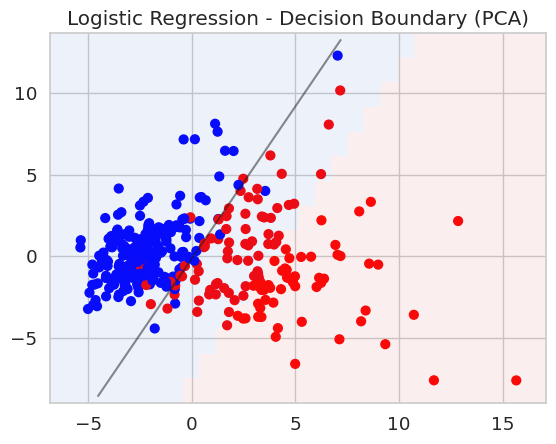

In [27]:
plot_decision_boundary_2d(
    model=lr_model,
    X_train=X_train,
    y_train=y_train,
    scaler=normalizations["Standard"],
    title="Logistic Regression - Decision Boundary (PCA)"
)

SVM Linear

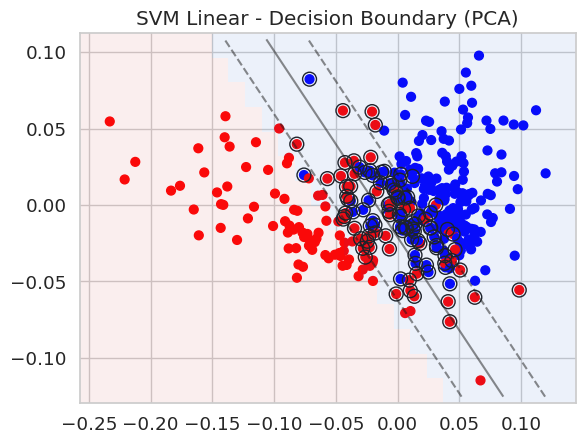

In [24]:
plot_decision_boundary_2d(
    model=svm_lin_model,
    X_train=X_train,
    y_train=y_train,
    scaler=normalizations["Mean Normalization"],
    title="SVM Linear - Decision Boundary (PCA)"
)

SVM RBF

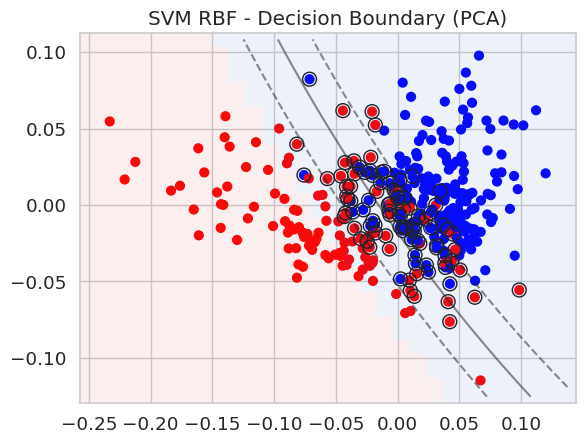

In [25]:
plot_decision_boundary_2d(
    model=svm_rbf_model,
    X_train=X_train,
    y_train=y_train,
    scaler=normalizations["Mean Normalization"],
    title="SVM RBF - Decision Boundary (PCA)"
)

## Confusion Matrix Comparison between models

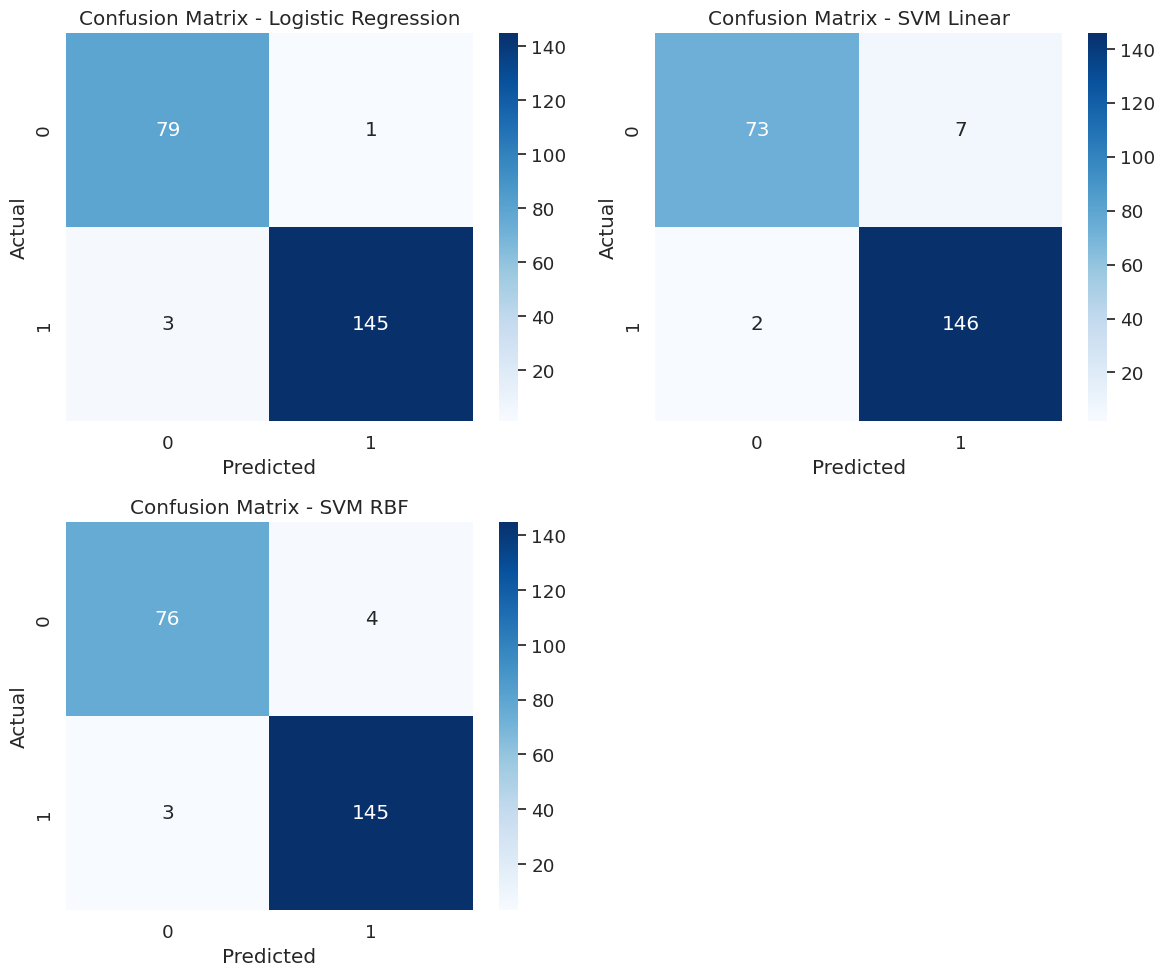

In [26]:
plot_confusion_matrix_comparison(y_test, lr_test_pred, svm_lin_test_pred, svm_rbf_test_pred)

## Conclusions

After completing the exercise, I observed that although SVM models with mean normalization showed a slight decrease in false negatives compared to the Logistic Regression model with standard normalization, the latter performed better overall in terms of global metrics.

This may be because the dataset is largely linearly separable, which favors linear models such as logistic regression. However, SVM models are not far behind in terms of performance, and their generalization ability could be better manifested with the arrival of new data or scenarios where classes are not so easily separable.